# 🩺 Skin Disease Classification — DenseNet201 (Head-Only, 50 Epochs) + XAI

## এই নোটবুকের আইডিয়া

আপনার ResNet50 নোটবুক আর আগের single-phase ViT নোটবুক থেকে idea নিয়ে বানানো, DenseNet201-এর জন্য:

- **কোনো fine-tuning ফেজ নেই** — ImageNet backbone সম্পূর্ণ **frozen** থাকে
  পুরো training জুড়ে, শুধু classification head **50 epochs** ট্রেইন হয়।
- Validation set শুধু checkpoint বাছাই (কোন epoch-এর weight সেভ হবে) আর
  EarlyStopping-এর জন্য ব্যবহার হয় — কোনো validation classification
  report/confusion matrix আলাদা করে দেখানো হয় না।
- ট্রেনিং শেষে **সরাসরি TEST সেটের** classification report + confusion matrix —
  এটাই একমাত্র রিপোর্ট করা রেজাল্ট।
- Loss/accuracy curve honest ভাবে আঁকা হয়েছে, কোনো visual trick ছাড়া।
- **Grad-CAM ও Grad-CAM++** (CNN-native, `tf-keras-vis` দিয়ে) — sample test
  ছবির উপর।
- **Sample dataset visualization** ও **Misclassified analysis** আগের মতোই।

ℹ️ ViT নোটবুকে যে Attention Rollout ছিল, সেটা transformer-specific (attention
weights লাগে) — DenseNet201 একটা CNN, তাই এখানে সেটার বদলে শুধু Grad-CAM
পরিবার (Grad-CAM, Grad-CAM++) ব্যবহার হয়েছে, যেটা আপনার থিসিসেও আগে থেকেই
প্ল্যান করা আছে।


In [1]:
# ⚡ ENVIRONMENT SETUP (Kaggle)
import os, sys, subprocess

def _ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

_ensure("tf-keras-vis", "tf_keras_vis")

import json, pickle, zipfile, shutil, random
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from PIL import Image
from matplotlib import cm
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import FileLink

from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

print(f"✅ TensorFlow version: {tf.__version__}")
print("👉 Kaggle notebook Settings-এ 'Internet' toggle ON আছে কিনা চেক করুন — ")
print("   ImageNet pretrained weights ডাউনলোড করার জন্য এটা লাগবে।")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 3.2 MB/s eta 0:00:00
✅ TensorFlow version: 2.20.0
👉 Kaggle notebook Settings-এ 'Internet' toggle ON আছে কিনা চেক করুন — 
   ImageNet pretrained weights ডাউনলোড করার জন্য এটা লাগবে।


In [2]:
# =========================
# 🔒 REPRODUCIBILITY SETUP
# =========================
import random

SEED = 42

os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("✅ Seed fixed:", SEED)


✅ Seed fixed: 42


In [3]:
# --- ১. পাথ ও প্যারামিটার সেটআপ (Kaggle version — Skin Disease, DenseNet201, head-only) ---

# ⚠️ এখানে তোমার ALREADY-SPLIT dataset-এর পাথ দাও —
# এই ফোল্ডারের ভেতরে সরাসরি train/  val/  test/  থাকতে হবে (প্রতিটার ভেতরে per-class subfolder)।
DATA_PATH = "/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2"   # <-- এখানে ঠিক পাথ বসাও

WORKING_DIR = "/kaggle/working/"
os.makedirs(WORKING_DIR, exist_ok=True)

RESUME_EPOCH_PATH = os.path.join(WORKING_DIR, "resume_epoch.pkl")

if not os.path.exists(DATA_PATH):
    print(f"⚠️ Path not found: {DATA_PATH}")
    print("👉 আপনি কি সঠিক Kaggle dataset input যোগ করেছেন?")
else:
    print(f"✅ DATA_PATH found: {DATA_PATH}")

_train_dir_for_classes = os.path.join(DATA_PATH, "train")
CLASS_NAMES = sorted([
    d for d in os.listdir(_train_dir_for_classes)
    if os.path.isdir(os.path.join(_train_dir_for_classes, d))
]) if os.path.exists(_train_dir_for_classes) else []

print(f"📂 মোট ক্লাস পাওয়া গেছে: {len(CLASS_NAMES)}")
for c in CLASS_NAMES:
    n = len(os.listdir(os.path.join(_train_dir_for_classes, c)))
    print(f"  📁 {c}: {n} images (train)")

# ---- Model config (DenseNet201) ----
MODEL_NAME  = "densenet201"
IMG_DIM     = 224
BATCH_SIZE  = 32
EPOCHS      = 20  # ⭐ single-phase head-only training — কোনো fine-tuning ফেজ নেই
EARLY_STOP_PATIENCE = 5

NB_CLASSES = len(CLASS_NAMES)

MODEL_DIR = os.path.join(WORKING_DIR, "models", MODEL_NAME)
os.makedirs(MODEL_DIR, exist_ok=True)
WEIGHT_PATH = os.path.join(MODEL_DIR, f"{MODEL_NAME}.weights.h5")
MISCLASS_DIR = os.path.join(WORKING_DIR, "misclassified_test")

print(f"\n✅ Model: DenseNet201  (input size {IMG_DIM}x{IMG_DIM})")
print(f"✅ MODEL_DIR: {MODEL_DIR}")
print(f"✅ EPOCHS: {EPOCHS}")
print(f"✅ NB_CLASSES: {NB_CLASSES}")


✅ DATA_PATH found: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2
📂 মোট ক্লাস পাওয়া গেছে: 15
  📁 Acne: 400 images (train)
  📁 Atopic Dermatitis: 400 images (train)
  📁 Contact Dermatitis: 400 images (train)
  📁 Eczema: 400 images (train)
  📁 Fungal Infection: 400 images (train)
  📁 Healthy Skin: 400 images (train)
  📁 Nail Fungal: 400 images (train)
  📁 Psoriasis: 400 images (train)
  📁 Scabies: 402 images (train)
  📁 Tinea Corporis: 400 images (train)
  📁 Tinea Cruris: 400 images (train)
  📁 Tinea Faciei: 403 images (train)
  📁 Tinea Versicolor: 400 images (train)
  📁 Urticaria: 400 images (train)
  📁 Vitiligo: 400 images (train)

✅ Model: DenseNet201  (input size 224x224)
✅ MODEL_DIR: /kaggle/working/models/densenet201
✅ EPOCHS: 20
✅ NB_CLASSES: 15


In [4]:
# =========================
# ✅ DATASET ALREADY SPLIT — শুধু VERIFY করা হচ্ছে (কোনো নতুন split/copy হবে না)
# =========================
GCS_PATH = DATA_PATH

required_splits = ["train", "val", "test"]
missing = [s for s in required_splits if not os.path.exists(os.path.join(GCS_PATH, s))]
if missing:
    raise FileNotFoundError(
        f"❌ এই ফোল্ডার(গুলো) পাওয়া যায়নি: {missing} — DATA_PATH ঠিক আছে কিনা চেক করুন।"
    )

print("✅ train/ val/ test/ — তিনটাই পাওয়া গেছে।\n")

nb_train_total = 0
for split in required_splits:
    split_path = os.path.join(GCS_PATH, split)
    class_dirs = [d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))]
    n = sum(len(os.listdir(os.path.join(split_path, d))) for d in class_dirs)
    print(f"  📁 {split}: {n} images, {len(class_dirs)} classes  ({split_path})")
    if split == "train":
        nb_train_total = n

NB_TRAIN = nb_train_total
print(f"\n✅ NB_TRAIN: {NB_TRAIN}")


✅ train/ val/ test/ — তিনটাই পাওয়া গেছে।

  📁 train: 6005 images, 15 classes  (/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/train)
  📁 val: 752 images, 15 classes  (/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/val)
  📁 test: 750 images, 15 classes  (/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/test)

✅ NB_TRAIN: 6005


## 🖼️ Sample Dataset Visualization

Train ফোল্ডার থেকে প্রতি ক্লাসের একটা করে র‍্যান্ডম sample ছবি।


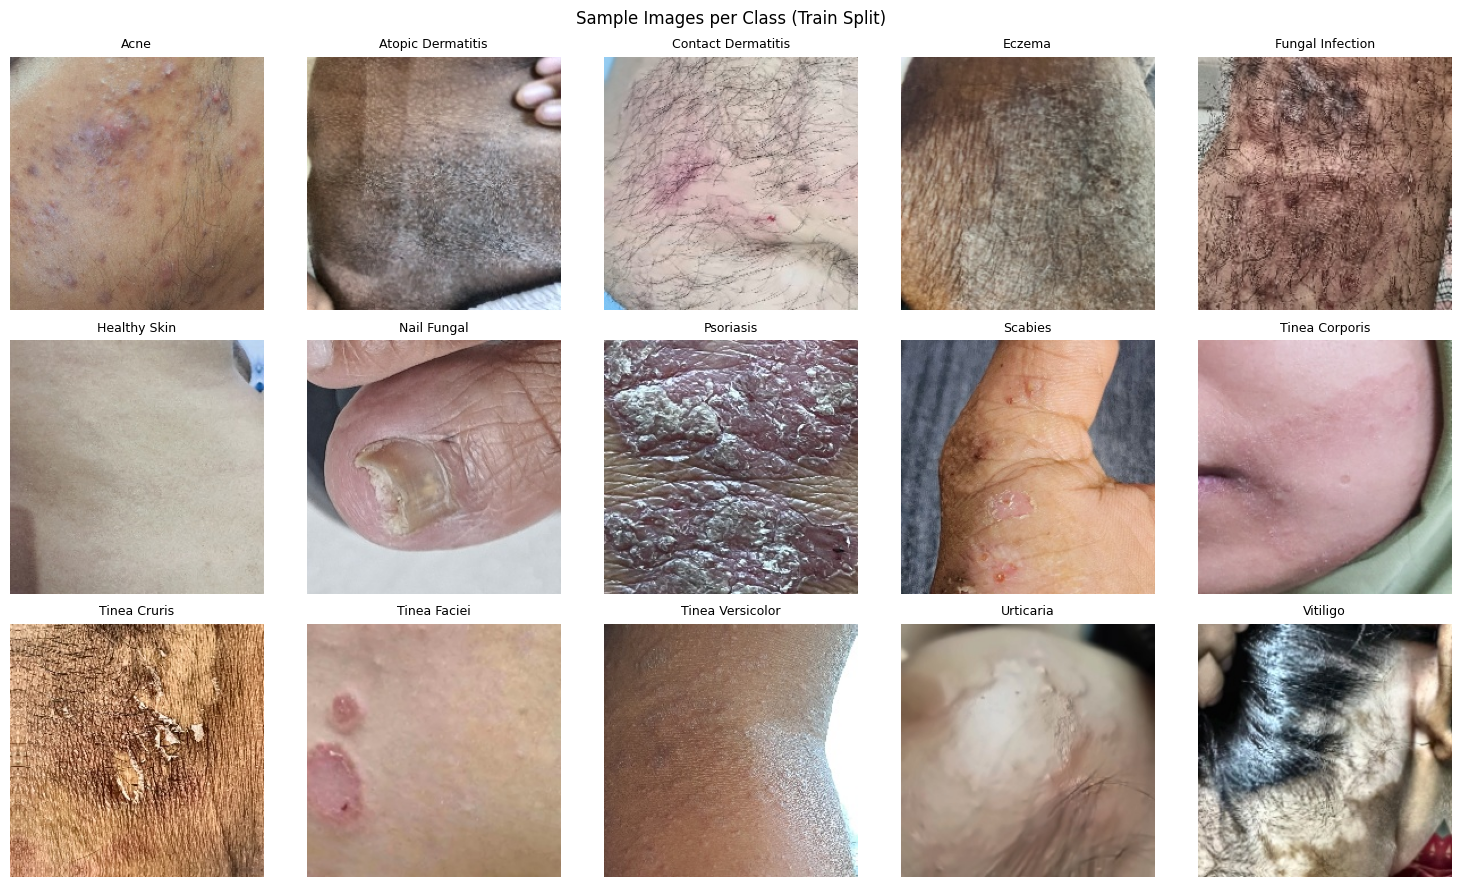

In [5]:
n_show = min(NB_CLASSES, 15)
sample_classes = CLASS_NAMES[:n_show]

cols = 5
rows = (n_show + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = np.array(axes).reshape(-1)

for ax, cname in zip(axes, sample_classes):
    class_dir = os.path.join(GCS_PATH, "train", cname)
    fname = random.choice(os.listdir(class_dir))
    img = Image.open(os.path.join(class_dir, fname)).convert("RGB")
    ax.imshow(img)
    ax.set_title(cname, fontsize=9)
    ax.axis("off")

for ax in axes[len(sample_classes):]:
    ax.axis("off")

plt.suptitle("Sample Images per Class (Train Split)")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "sample_dataset.png"), dpi=150)
plt.show()


In [6]:
# GPU Setup
gpus = tf.config.list_physical_devices('GPU')
print("🖥️ Visible GPUs:", gpus)
strategy = tf.distribute.get_strategy()

STEPS_PER_EPOCH = max(1, NB_TRAIN // BATCH_SIZE)
print(f"✅ BATCH_SIZE: {BATCH_SIZE}")
print(f"✅ STEPS_PER_EPOCH: {STEPS_PER_EPOCH}")


🖥️ Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
✅ BATCH_SIZE: 32
✅ STEPS_PER_EPOCH: 187


In [7]:
import os
import tensorflow as tf

# Medical-Safe Data Pipeline — train / val / test সম্পূর্ণ আলাদা
def data_input_fn(mode):
    folder_path = os.path.join(GCS_PATH, mode)
    print(f"🔄 Loading {mode} from: {folder_path}")

    if not os.path.exists(folder_path):
        raise FileNotFoundError(f"Folder not found: {folder_path}")

    # ❌ অগমেন্টেশন তৈরি করার অংশটি কমেন্ট করা হলো 
    # if mode == "train":
    #     augmentation = tf.keras.Sequential([
    #         tf.keras.layers.RandomRotation(factor=0.03, seed=SEED),
    #         tf.keras.layers.RandomZoom(0.05, 0.05, seed=SEED),
    #         tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    #         tf.keras.layers.RandomBrightness(0.03, seed=SEED),
    #     ], name="augmentation")

    raw_dataset = tf.keras.utils.image_dataset_from_directory(
        folder_path,
        labels='inferred',
        label_mode='categorical',
        batch_size=None,
        image_size=(IMG_DIM, IMG_DIM),
        shuffle=False,
        seed=SEED
    )

    n_samples = tf.data.experimental.cardinality(raw_dataset).numpy()

    def preprocess(image, label):
        image = tf.keras.applications.densenet.preprocess_input(image)
        return image, label

    dataset = raw_dataset.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.cache()

    if mode == "train":
        dataset = dataset.shuffle(buffer_size=max(int(n_samples), 1), seed=SEED,
                                   reshuffle_each_iteration=True)

    dataset = dataset.batch(BATCH_SIZE)

    if mode == "train":
        # ❌ অগমেন্টেশন অ্যাপ্লাই করার ম্যাপ ফাংশনটিও কমেন্ট করা হলো
        # dataset = dataset.map(lambda x, y: (augmentation(x, training=True), y),
        #                        num_parallel_calls=tf.data.AUTOTUNE)
        
        # ✅ শুধুমাত্র repeat() রাখা হলো, যা ট্রেনিংয়ের জন্য জরুরি
        dataset = dataset.repeat()

    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

print("\n" + "="*50)
print("📂 LOADING DATASETS (train / val / test — সম্পূর্ণ আলাদা)")
print("="*50)

train_ds = data_input_fn("train")
eval_ds  = data_input_fn("val")
test_ds  = data_input_fn("test")
print("✅ train_ds, eval_ds (val), test_ds — সব READY!")


📂 LOADING DATASETS (train / val / test — সম্পূর্ণ আলাদা)
🔄 Loading train from: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/train
Found 6005 files belonging to 15 classes.


I0000 00:00:1785799489.550131      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785799489.553513      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


🔄 Loading val from: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/val
Found 752 files belonging to 15 classes.
🔄 Loading test from: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/test
Found 750 files belonging to 15 classes.
✅ train_ds, eval_ds (val), test_ds — সব READY!


In [8]:
# Class Weight Calculation for Balanced Training (শুধু TRAIN ফোল্ডার থেকে)
print("\n" + "="*50)
print("⚖️ CALCULATING CLASS WEIGHTS")
print("="*50)

train_dir = os.path.join(GCS_PATH, 'train')
class_folders = sorted([f for f in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, f))])

y_train_list = []
for i, folder in enumerate(class_folders):
    folder_path = os.path.join(train_dir, folder)
    count = len(os.listdir(folder_path))
    y_train_list.extend([i] * count)
    print(f"  {folder}: {count} images")

weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_list),
    y=y_train_list
)
class_weights = dict(enumerate(weights))
print("✅ Class Weights:", class_weights)



⚖️ CALCULATING CLASS WEIGHTS
  Acne: 400 images
  Atopic Dermatitis: 400 images
  Contact Dermatitis: 400 images
  Eczema: 400 images
  Fungal Infection: 400 images
  Healthy Skin: 400 images
  Nail Fungal: 400 images
  Psoriasis: 400 images
  Scabies: 402 images
  Tinea Corporis: 400 images
  Tinea Cruris: 400 images
  Tinea Faciei: 403 images
  Tinea Versicolor: 400 images
  Urticaria: 400 images
  Vitiligo: 400 images
✅ Class Weights: {0: np.float64(1.0008333333333332), 1: np.float64(1.0008333333333332), 2: np.float64(1.0008333333333332), 3: np.float64(1.0008333333333332), 4: np.float64(1.0008333333333332), 5: np.float64(1.0008333333333332), 6: np.float64(1.0008333333333332), 7: np.float64(1.0008333333333332), 8: np.float64(0.9958540630182421), 9: np.float64(1.0008333333333332), 10: np.float64(1.0008333333333332), 11: np.float64(0.9933829611248967), 12: np.float64(1.0008333333333332), 13: np.float64(1.0008333333333332), 14: np.float64(1.0008333333333332)}


In [9]:
print("\n" + "="*50)
print("🏗️ BUILDING DENSENET201 MODEL")
print("="*50)

USE_XLA = True
USE_MIXED_PRECISION = True
if USE_MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print("✅ Mixed precision (mixed_float16) enabled")

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=EPOCHS * STEPS_PER_EPOCH
)

with strategy.scope():
    base_model = tf.keras.applications.DenseNet201(
        input_shape=(IMG_DIM, IMG_DIM, 3),
        include_top=False,
        weights='imagenet'
    )
    # ⭐ কোনো fine-tuning ফেজ নেই — backbone সম্পূর্ণ FROZEN থাকবে পুরো training জুড়ে।
    #    শুধু নতুন classification head train হবে।
    base_model.trainable = False

    inputs = base_model.input
    x = base_model.output
    x_avg = tf.keras.layers.GlobalAveragePooling2D()(x)
    x_max = tf.keras.layers.GlobalMaxPooling2D()(x)
    x = tf.keras.layers.Concatenate()([x_avg, x_max])
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.4)(x)
    x = tf.keras.layers.Dense(256, activation='swish')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(NB_CLASSES, activation="softmax", dtype='float32')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.10),
        metrics=['accuracy', tf.keras.metrics.Recall(name='recall')],
        jit_compile=USE_XLA
    )

trainable = sum(np.prod(v.shape) for v in model.trainable_weights)
total = sum(np.prod(v.shape) for v in model.weights)
print(f"✅ Trainable params (head-only, backbone frozen): {trainable:,} / {total:,}")
model.summary()



🏗️ BUILDING DENSENET201 MODEL
✅ Mixed precision (mixed_float16) enabled
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Trainable params (head-only, backbone frozen): 995,343 / 19,325,519


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/trainer.py:212: UserWarning: Model doesn't support `jit_compile=True`. Proceeding with `jit_compile=False`.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 19,325,519 (73.72 MB)

 Trainable params: 995,343 (3.80 MB)

 Non-trainable params: 18,330,176 (69.92 MB)

In [10]:
# --- Callbacks ---
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=EARLY_STOP_PATIENCE,
    verbose=1,
    restore_best_weights=True
)

model_autosave = tf.keras.callbacks.ModelCheckpoint(
    WEIGHT_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1,
    save_weights_only=True
)
# ⚠️ শুধু checkpoint বাছাই আর early-stopping-এর জন্য val ব্যবহার হচ্ছে —
#    আলাদা করে কোনো val classification report/confusion matrix দেখানো হবে না।
callbacks = [model_autosave, early_stopping]

print("✅ Callbacks ready")


✅ Callbacks ready


In [11]:
# 🚀 TRAINING — single phase, backbone frozen, up to 50 epochs
print("\n" + "="*50)
print(f"🚀 TRAINING — {EPOCHS} epochs, backbone FROZEN, head-only (DenseNet201)")
print("="*50)

history = model.fit(
    train_ds,
    steps_per_epoch=STEPS_PER_EPOCH,
    epochs=EPOCHS,
    validation_data=eval_ds,
    callbacks=callbacks,
    class_weight=class_weights
)



🚀 TRAINING — 20 epochs, backbone FROZEN, head-only (DenseNet201)
Epoch 1/20
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.7263 - loss: 1.4855 - recall: 0.6436
Epoch 1: val_accuracy improved from None to 0.84176, saving model to /kaggle/working/models/densenet201/densenet201.weights.h5

Epoch 1: finished saving model to /kaggle/working/models/densenet201/densenet201.weights.h5
187/187 ━━━━━━━━━━━━━━━━━━━━ 83s 246ms/step - accuracy: 0.8615 - loss: 1.0746 - recall: 0.8005 - val_accuracy: 0.8418 - val_loss: 1.0758 - val_recall: 0.6396
Epoch 2/20
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.9730 - loss: 0.7602 - recall: 0.9261
Epoch 2: val_accuracy improved from 0.84176 to 0.88564, saving model to /kaggle/working/models/densenet201/densenet201.weights.h5

Epoch 2: finished saving model to /kaggle/working/models/densenet201/densenet201.weights.h5
187/187 ━━━━━━━━━━━━━━━━━━━━ 37s 197ms/step - accuracy: 0.9769 - loss: 0.7440 - recall: 0.9362 - val_accuracy: 0.8856 - val

## 📈 Training Curves — Loss & Accuracy (Train vs Val)

Honest curves, কোনো crop/scale trick ছাড়া। Backbone পুরো training জুড়ে frozen
থাকায় trainable parameter কম — এটাই gap কমানোর legitimate উপায়।


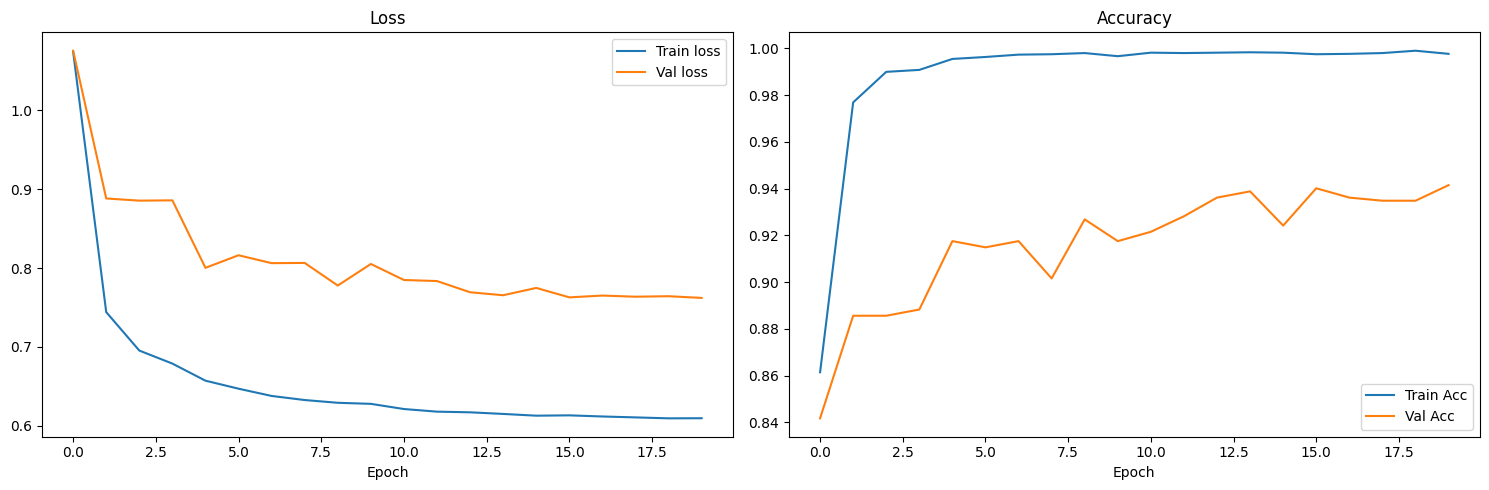

In [12]:
def plot_history(history, model_dir, iden):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(15, 5))
    ax_loss.plot(history.epoch, history.history["loss"], label="Train loss")
    ax_loss.plot(history.epoch, history.history["val_loss"], label="Val loss")
    ax_loss.set_title("Loss")
    ax_loss.set_xlabel("Epoch")
    ax_loss.legend()
    ax_acc.plot(history.epoch, history.history["accuracy"], label="Train Acc")
    ax_acc.plot(history.epoch, history.history["val_accuracy"], label="Val Acc")
    ax_acc.set_title("Accuracy")
    ax_acc.set_xlabel("Epoch")
    ax_acc.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(model_dir, f"{iden}_metrics.png"), dpi=150)
    plt.show()

plot_history(history, MODEL_DIR, MODEL_NAME)


## 🎯 Final Evaluation — TEST SET ONLY (Classification Report + Confusion Matrix)

কোনো validation report নেই — সরাসরি সেরা checkpoint দিয়ে TEST সেটের উপর
পূর্ণাঙ্গ classification report ও confusion matrix।


✅ Best weights loaded
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 158ms/step - accuracy: 0.9573 - loss: 0.7625 - recall: 0.8427
✅ Final TEST Accuracy: 95.73%
✅ Final TEST Recall:   84.27%

⏳ Processing Predictions on TEST set...


  0%|          | 0/24 [00:00<?, ?it/s]

2026-08-03 23:46:09.102791: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



📋 FINAL CLASSIFICATION REPORT (TEST SET, n=750)
                   precision  recall f1-score support
Acne                  0.9400  0.9400   0.9400      50
Atopic Dermatitis     0.9048  0.7600   0.8261      50
Contact Dermatitis    1.0000  1.0000   1.0000      50
Eczema                0.9796  0.9600   0.9697      50
Fungal Infection      1.0000  0.9800   0.9899      50
Healthy Skin          1.0000  0.9800   0.9899      50
Nail Fungal           1.0000  1.0000   1.0000      50
Psoriasis             1.0000  0.9400   0.9691      50
Scabies               0.8909  0.9800   0.9333      50
Tinea Corporis        0.9583  0.9200   0.9388      50
Tinea Cruris          0.9804  1.0000   0.9901      50
Tinea Faciei          0.9615  1.0000   0.9804      50
Tinea Versicolor      1.0000  0.9200   0.9583      50
Urticaria             0.9800  0.9800   0.9800      50
Vitiligo              0.8065  1.0000   0.8929      50
accuracy                               0.9573     750
macro avg             0.9601  0.9

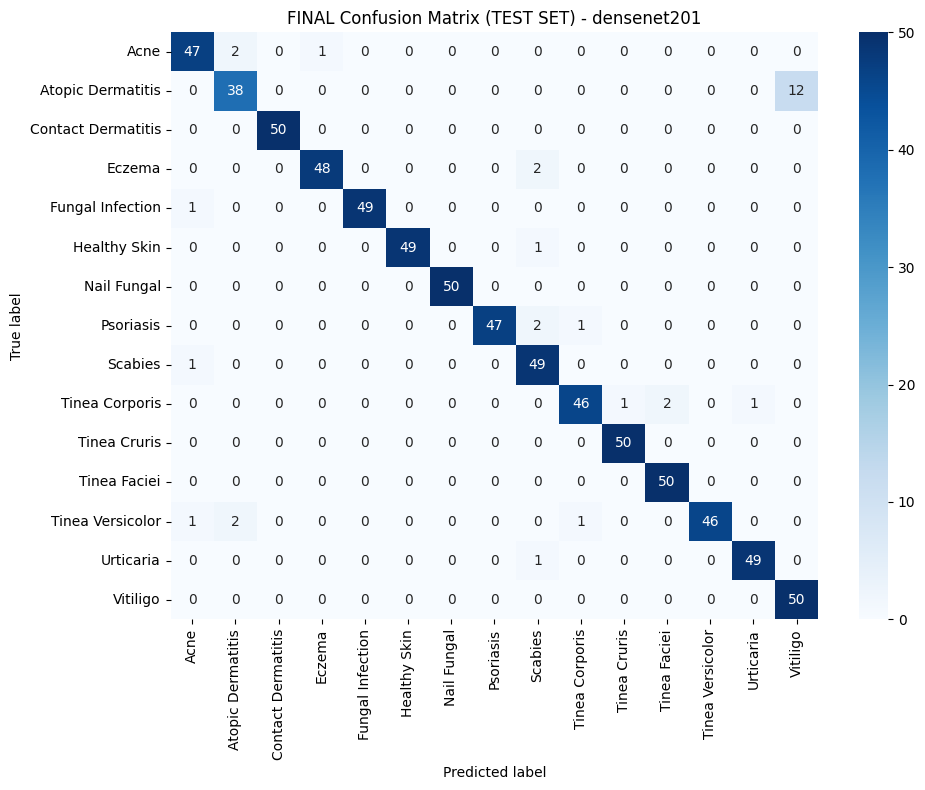

In [19]:
# Load best checkpoint (EarlyStopping-এর restore_best_weights ইতিমধ্যেই সেরাটা রেখেছে,
# তারপরও নিশ্চিত হতে ফাইল থেকে আবার লোড করা হচ্ছে)
model.load_weights(WEIGHT_PATH)
print("✅ Best weights loaded")

def get_predictions(dataset):
    gts, preds = [], []
    for x, y in tqdm(dataset):
        y_pred = model.predict(x, verbose=0)
        gts.extend(np.argmax(y, axis=1))
        preds.extend(np.argmax(y_pred, axis=1))
    return np.array(gts), np.array(preds)

def plot_confusion(gts, preds, class_names, title, save_path=None):
    con_mat = confusion_matrix(gts, preds)   # raw counts, NOT normalized
    plt.figure(figsize=(10, 8))
    sn.heatmap(con_mat, annot=True, fmt='d', cmap='Blues',
               xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(MODEL_DIR, save_path), dpi=150)
    plt.show()
    return con_mat

def print_formatted_report(gts, preds, class_names, title, save_path=None):
    """Print classification report as a 4-decimal formatted table (image style)."""
    report_dict = classification_report(gts, preds, target_names=class_names,
                                         output_dict=True, zero_division=0)
    # 'accuracy' comes back as a plain float in output_dict -> reshape it so it
    # matches the image style: blank precision/recall, f1-score = accuracy, support = total n
    total_support = int(report_dict["macro avg"]["support"])
    acc_value = report_dict["accuracy"]
    report_dict["accuracy"] = {
        "precision": None,
        "recall": None,
        "f1-score": acc_value,
        "support": total_support,
    }
    report_df = pd.DataFrame(report_dict).transpose()
    disp = pd.DataFrame(index=report_df.index, columns=["precision", "recall", "f1-score", "support"])
    for col in ["precision", "recall", "f1-score"]:
        disp[col] = report_df[col].apply(lambda x: "" if pd.isna(x) else f"{x:.4f}")
    disp["support"] = report_df["support"].apply(lambda x: "" if pd.isna(x) else f"{int(x)}")
    print("\n" + "="*50)
    print(title)
    print("="*50)
    print(disp.to_string())
    if save_path:
        with open(save_path, "w") as f:
            f.write(disp.to_string())
    return report_dict

test_loss, test_acc, test_recall = model.evaluate(test_ds)
print(f"✅ Final TEST Accuracy: {test_acc*100:.2f}%")
print(f"✅ Final TEST Recall:   {test_recall*100:.2f}%")

print("\n⏳ Processing Predictions on TEST set...")
test_gts, test_preds = get_predictions(test_ds)

report_dict = print_formatted_report(
    test_gts, test_preds, CLASS_NAMES,
    f"📋 FINAL CLASSIFICATION REPORT (TEST SET, n={len(test_gts)})",
    save_path=os.path.join(MODEL_DIR, "final_test_classification_report.txt")
)

con_mat = plot_confusion(test_gts, test_preds, CLASS_NAMES,
                          f"FINAL Confusion Matrix (TEST SET) - {MODEL_NAME}",
                          "confusion_matrix.png")

## ❌ Misclassified Analysis (TEST SET)


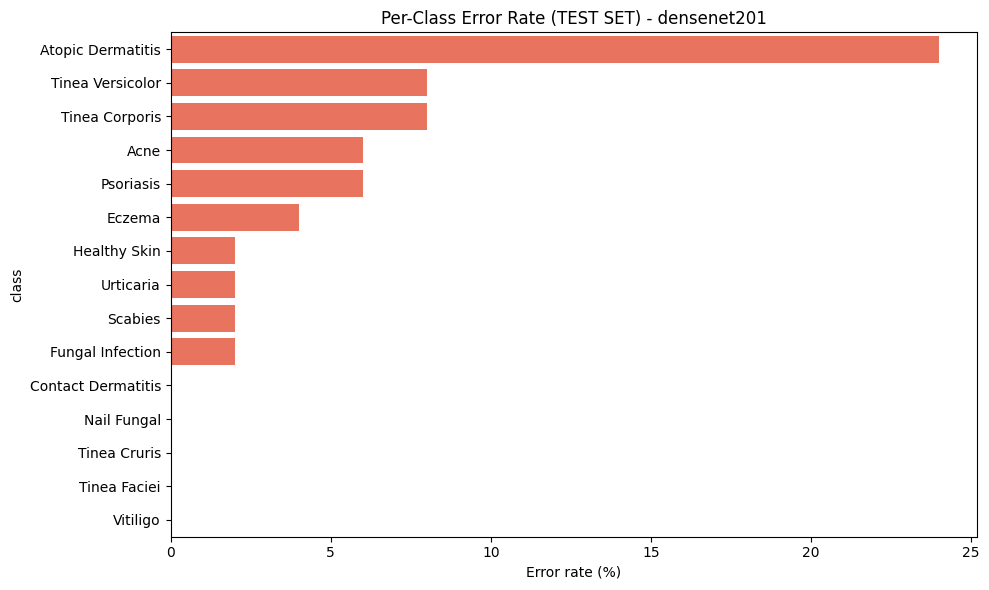


🔎 সবচেয়ে বেশি সমস্যাযুক্ত ক্লাস: Atopic Dermatitis (12 ভুল, 24.0% error rate)
✅ মোট 32টা misclassified ছবি `/kaggle/working/misclassified_test`-এ সেভ হয়েছে।


In [14]:
os.makedirs(MISCLASS_DIR, exist_ok=True)

per_class_total = {c: 0 for c in CLASS_NAMES}
per_class_wrong = {c: 0 for c in CLASS_NAMES}
for gt, pred in zip(test_gts, test_preds):
    cname = CLASS_NAMES[gt]
    per_class_total[cname] += 1
    if gt != pred:
        per_class_wrong[cname] += 1

err_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "wrong": [per_class_wrong[c] for c in CLASS_NAMES],
    "total": [per_class_total[c] for c in CLASS_NAMES],
})
err_df["error_rate_%"] = (err_df["wrong"] / err_df["total"] * 100).round(2)
err_df = err_df.sort_values("error_rate_%", ascending=False)
err_df.to_csv(os.path.join(MODEL_DIR, "per_class_error_summary.csv"), index=False)

plt.figure(figsize=(10, 6))
sn.barplot(data=err_df, y="class", x="error_rate_%", color="tomato")
plt.title(f"Per-Class Error Rate (TEST SET) - {MODEL_NAME}")
plt.xlabel("Error rate (%)")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "per_class_error_analysis.png"), dpi=150)
plt.show()

worst = err_df.iloc[0]
print(f"\n🔎 সবচেয়ে বেশি সমস্যাযুক্ত ক্লাস: {worst['class']} "
      f"({int(worst['wrong'])} ভুল, {worst['error_rate_%']}% error rate)")

# ⚠️ test_ds shuffle=False, তাই file_paths এর order dataset iteration order-এর সাথে মেলে
test_dir = os.path.join(GCS_PATH, "test")
test_filepaths = []
for cname in CLASS_NAMES:
    class_dir = os.path.join(test_dir, cname)
    for fname in sorted(os.listdir(class_dir)):
        test_filepaths.append(os.path.join(class_dir, fname))

idx = 0
for filepath, gt, pred in zip(test_filepaths, test_gts, test_preds):
    if gt != pred:
        true_name = CLASS_NAMES[gt]
        pred_name = CLASS_NAMES[pred]
        out_dir = os.path.join(MISCLASS_DIR, f"true_{true_name}_pred_{pred_name}")
        os.makedirs(out_dir, exist_ok=True)
        shutil.copy(filepath, os.path.join(out_dir, os.path.basename(filepath)))
        idx += 1
print(f"✅ মোট {idx}টা misclassified ছবি `{MISCLASS_DIR}`-এ সেভ হয়েছে।")


## 🔍 Explainability (XAI) — Grad-CAM ও Grad-CAM++

DenseNet201-এর শেষ conv block-এর activation ব্যবহার করে মডেল কোন অংশ দেখে
সিদ্ধান্ত নিচ্ছে সেটা visualize করা হচ্ছে। `tf-keras-vis` লাইব্রেরি auto-detect
করে শেষ convolutional layer বের করে নেয়।


In [15]:
# --- Grad-CAM / Grad-CAM++ setup ---
replace2linear = ReplaceToLinear()

gradcam = Gradcam(model, model_modifier=replace2linear, clone=True)
gradcampp = GradcamPlusPlus(model, model_modifier=replace2linear, clone=True)

print("✅ Grad-CAM ও Grad-CAM++ রেডি")


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/trainer.py:212: UserWarning: Model doesn't support `jit_compile=True`. Proceeding with `jit_compile=False`.
  warnings.warn(


✅ Grad-CAM ও Grad-CAM++ রেডি


2026-08-03 23:38:50.542139: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-08-03 23:38:57.110452: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

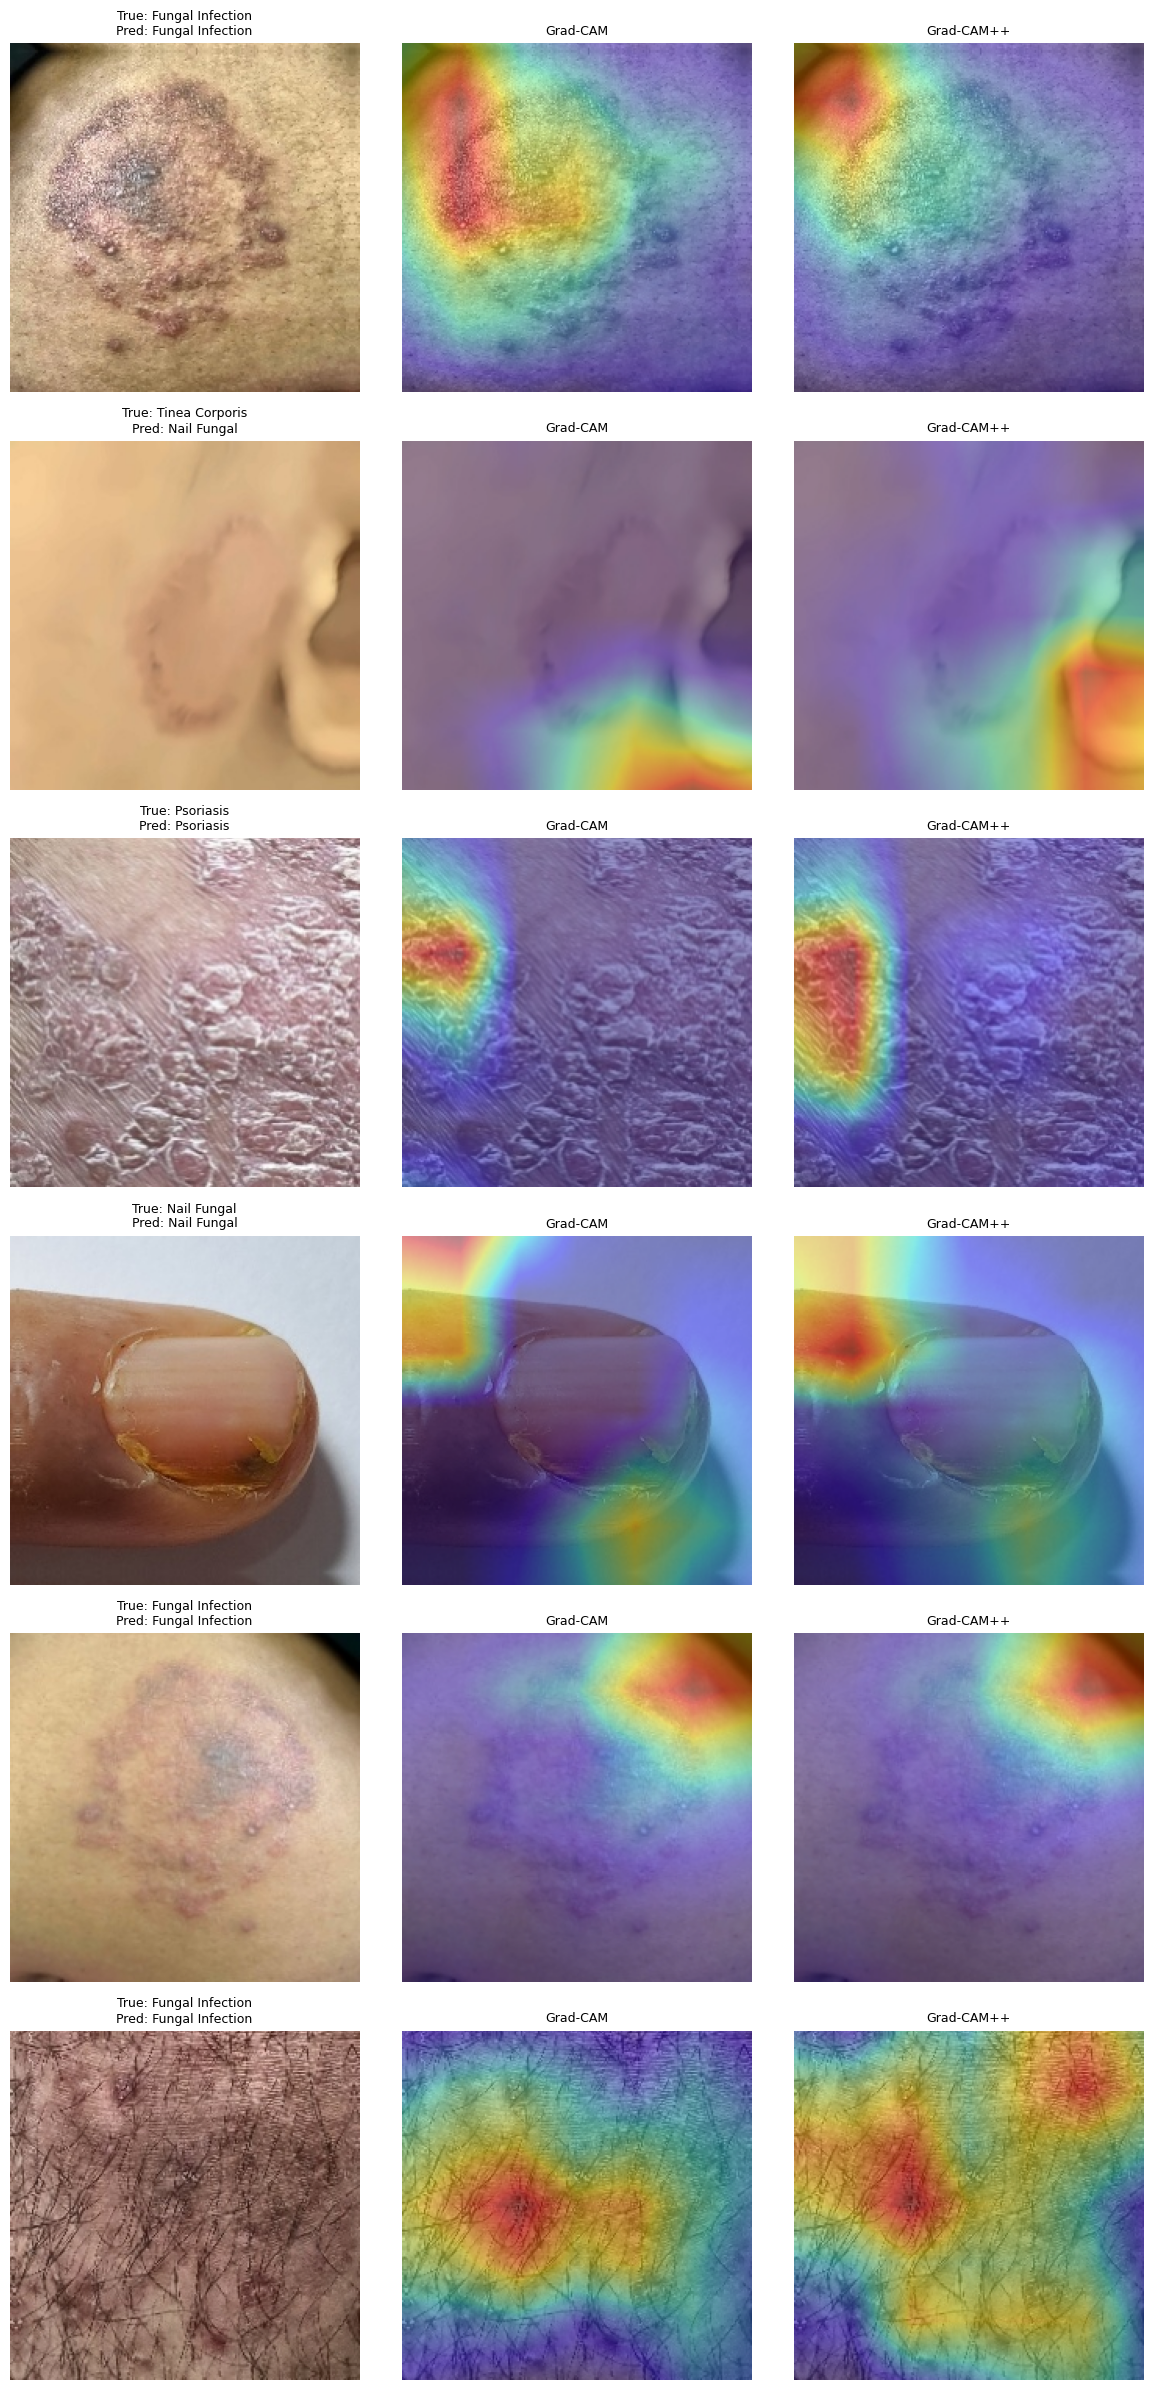

In [16]:
# --- Grad-CAM / Grad-CAM++ — কয়েকটা sample TEST ছবির উপর ---

n_samples = 6
sample_filepaths_labels = list(zip(test_filepaths, test_gts))
sample_choices = random.sample(sample_filepaths_labels, min(n_samples, len(sample_filepaths_labels)))

fig, axes = plt.subplots(len(sample_choices), 3, figsize=(12, 4 * len(sample_choices)))
if len(sample_choices) == 1:
    axes = axes.reshape(1, -1)

for row, (filepath, true_label) in enumerate(sample_choices):
    raw_img = Image.open(filepath).convert("RGB").resize((IMG_DIM, IMG_DIM))
    raw_arr = np.array(raw_img).astype(np.float32)

    model_input = tf.keras.applications.densenet.preprocess_input(raw_arr.copy())
    model_input = np.expand_dims(model_input, axis=0)

    pred_probs = model.predict(model_input, verbose=0)[0]
    pred_label = int(np.argmax(pred_probs))

    score = CategoricalScore([pred_label])

    gc_map = gradcam(score, model_input, penultimate_layer=-1)[0]
    gcpp_map = gradcampp(score, model_input, penultimate_layer=-1)[0]

    def overlay(raw_uint8, cam_map):
        heatmap = np.uint8(cm.jet(cam_map)[..., :3] * 255)
        return np.uint8(heatmap * 0.4 + raw_uint8 * 0.6)

    raw_uint8 = raw_arr.astype(np.uint8)
    gc_overlay = overlay(raw_uint8, gc_map)
    gcpp_overlay = overlay(raw_uint8, gcpp_map)

    title_prefix = f"True: {CLASS_NAMES[true_label]}\nPred: {CLASS_NAMES[pred_label]}"
    axes[row, 0].imshow(raw_uint8); axes[row, 0].set_title(title_prefix, fontsize=9); axes[row, 0].axis("off")
    axes[row, 1].imshow(gc_overlay); axes[row, 1].set_title("Grad-CAM", fontsize=9); axes[row, 1].axis("off")
    axes[row, 2].imshow(gcpp_overlay); axes[row, 2].set_title("Grad-CAM++", fontsize=9); axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "xai_gradcam.png"), dpi=150)
plt.show()


## 💾 Save Model + Zip Results


In [17]:
model.save(os.path.join(MODEL_DIR, f"{MODEL_NAME}_skin_model.keras"))
print(f"✅ Model saved")
display(FileLink(WEIGHT_PATH))

results_zip = os.path.join(WORKING_DIR, f"{MODEL_NAME}_results.zip")
with zipfile.ZipFile(results_zip, 'w') as zipf:
    for fname in ["confusion_matrix.png", "per_class_error_analysis.png",
                  "sample_dataset.png", "xai_gradcam.png",
                  f"{MODEL_NAME}_metrics.png",
                  "final_test_classification_report.txt", "per_class_error_summary.csv"]:
        fpath = os.path.join(MODEL_DIR, fname)
        if os.path.exists(fpath):
            zipf.write(fpath, arcname=fname)

print(f"✅ Results zipped: {results_zip}")
display(FileLink(results_zip))


✅ Model saved


/kaggle/working/models/densenet201/densenet201.weights.h5

✅ Results zipped: /kaggle/working/densenet201_results.zip


/kaggle/working/densenet201_results.zip